# 10강 실습: NSMC 형태소 분석과 단어구름

네이버 영화평 20만 편(NSMC)을 Kiwi로 형태소 분석하고, 명사의 빈도를 세어 단어구름을 그린다.

- 이 노트북은 저장소 **맨 위**(`/workspaces/LDS2026`)에 두어야 `data/nsmc/…`와 `plots/…` 경로가 맞는다.
- 처음 한 번은 터미널에서 아래 두 줄을 실행한다. `kiwipiepy`는 분석 모델(88MB)을 함께 받으니 시간이 걸린다. `fonts-nanum`은 7강에서 미뤄 둔 한글 글꼴로, 오늘 단어구름에 쓴다.
- 영화평 파일은 「3. 데이터 읽기」 앞에서 터미널로 내려받는다. `plots/` 폴더는 7강에서 만들었다.
- 커밋하기 전에는 [Restart] 후 [Run All]로 위에서 아래까지 한 번에 돌려 본다.

```bash
pip install kiwipiepy wordcloud
sudo apt-get update && sudo apt-get install -y fonts-nanum
```

## 0. 준비

네 가지를 불러온다.

- `name`: 9강에서 쓴 `unicodedata.name`. 글자의 유니코드 이름을 알려 준다.
- **pandas**: 7강에서 쓴 표 라이브러리
- **Kiwi**: 한국어 형태소 분석기. `Kiwi()`로 분석기를 하나 만들어 `kiwi`에 담아 두고 끝까지 쓴다.
- **WordCloud**: 단어구름을 그리는 라이브러리

In [1]:
from unicodedata import name
import pandas as pd
from kiwipiepy import Kiwi
from wordcloud import WordCloud

kiwi = Kiwi()

오늘 쓸 영화평 20만 편 가운데 첫 편이다. 이 리뷰는 몇 단어인가?

`split()`은 공백으로 자른다. 결과는 **셋**이다. 그런데 맞춤법대로 띄어 쓰면(`어릴 때 보고 지금 다시 봐도 재밌어요ㅋㅋ`) **일곱**이 되고, 뜻을 가진 조각으로 나누면 **열둘**이 된다.

공백이 자르는 것은 **어절**(語節)이다. 어절의 수는 쓴 사람이 어떻게 띄었느냐에 달렸다. 한국어는 어간에 조사와 어미가 겹겹이 붙는 교착어라서, `영화가`, `영화를`, `영화는`이 공백으로는 서로 다른 타입으로 세어진다. 8강은 "무엇을 하나로 셀 것인가", 9강은 "글자 하나는 무엇인가"를 물었다. 오늘은 **한국어에서 단어 하나는 무엇인가**를 묻는다.

In [2]:
s = '어릴때보고 지금다시봐도 재밌어요ㅋㅋ'
print(s.split())
print(len(s.split()))

['어릴때보고', '지금다시봐도', '재밌어요ㅋㅋ']
3


## 1. 첫 분석

분석기는 판이 바뀌면 결과가 바뀐다. 슬라이드의 모든 수는 **0.23.2**로 얻었다. 여러분의 수가 슬라이드와 다르면 판본부터 확인하고, 보고서에도 판본을 적는다.

In [3]:
import kiwipiepy
print(kiwipiepy.__version__)

0.23.2


`kiwi.tokenize`는 문자열을 받아 형태소(`Token`)의 목록을 돌려준다.

- `t.form`: 형태. 원문의 조각이 아니라 **되살린 기본형**이다.
- `t.tag`: 품사 태그. 세종 말뭉치의 태그를 바탕으로 한다. `NNG` 일반 명사, `VV` 동사, `VA` 형용사, `MAG` 일반 부사, `EC` 연결 어미, `EF` 종결 어미, `ETM` 관형형 전성 어미, `SW` 기타 기호.

`어릴`은 `어리/VA`+`ᆯ/ETM`, `봐도`는 `보/VV`+`어도/EC`다. `ㅋㅋ`도 `SW`로 한 자리를 차지한다. 셋이던 어절이 **열두 형태소**가 되었다.

형태소 분석은 세 가지 일을 한다. 어절 안에서 경계를 **가르고**, 바뀐 모양을 사전에 오른 기본형으로 **되살리고**, 형태소마다 **품사를 붙인다**.

In [4]:
for t in kiwi.tokenize(s):
    print(t.form, t.tag)

어리 VA
ᆯ ETM
때 NNG
보 VV
고 EC
지금 MAG
다시 MAG
보 VV
어도 EC
재밌 VA
어요 EF
ㅋㅋ SW


`t.start`는 그 형태소가 원문의 몇 번째 글자에서 시작하는지, `t.len`은 몇 글자에 걸쳐 있는지다. `t.end`는 `t.start + t.len`이다.

`오`는 원문의 `와` 한 글자에서 왔고, `어서`는 `와서` 두 글자에 걸쳐 있다. **두 형태소가 한 글자를 나누어 가진다.** `와서`를 어디서 잘라도 `오`는 나오지 않으니, 형태소는 문자열의 조각이 아니다. `form`을 이어 붙여도 원문이 되지 않으므로 원문이 필요하면 `start`와 `len`으로 되짚는다.

8강의 동요 코퍼스는 `와서`를 `오 아서`로 적었지만, Kiwi는 `아/어`로 갈리는 어미를 `어` 쪽으로 모아 적는다.

In [5]:
w = '와서 보니'
for t in kiwi.tokenize(w):
    print(t.form, t.tag, t.start, t.len, w[t.start:t.end])

오 VV 0 1 와
어서 EC 0 2 와서
보 VV 3 1 보
니 EC 4 1 니


Kiwi는 어미의 첫머리에 오는 받침 ㄴ·ㄹ을 **종성 자모**로 적는다. 9강의 NFD에서 본 바로 그 `U+11AB`(HANGUL JONGSEONG NIEUN)다.

키보드로 친 ㄴ은 **호환 자모** `U+3134`(HANGUL LETTER NIEUN)라서 `==`가 `False`가 된다. 눈으로는 같아도 다른 글자다. 어미로 검색할 때 조심한다. `kiwi.tokenize(..., compatible_jamo=True)`로 받으면 호환 자모가 나온다.

In [6]:
ts = kiwi.tokenize('추천한다')
print([t.form for t in ts])
print(ts[2].form == 'ㄴ다')
print(name(ts[2].form[0]))
print(name('ㄴ'))

['추천', '하', 'ᆫ다']
False
HANGUL JONGSEONG NIEUN
HANGUL LETTER NIEUN


## 2. 기계가 나눈 것

8강 동요 코퍼스 [7]행의 원문을 Kiwi로 나누어, 8강에서 사람이 나눈 것과 견준다. 사람이 나눈 것은 이랬다.

`산 위 에서 불 는 바람 시원하 은 바람 그 바람 은 좋 은 바람 고맙 은 바람`

- **오류**: `부는`을 명사 `부`와 보조사 `는`으로 봤다. 같은 `부는`을 `바람이 부는 날`에서는 `불`로 바르게 되살렸다. 분석기는 가능한 분석을 모두 만든 뒤 앞뒤 맥락으로 가장 그럴듯한 것을 고르는데, 여기서는 잘못 골랐다.
- **깊이**: `시원한`을 어근 `시원`과 접미사 `하`로 한 번 더 쪼갰다.
- **표기**: 관형형 어미를 사람은 모두 `은`으로, Kiwi는 모음 뒤에서 `ᆫ`으로 적었다.

분석 결과에는 분석기의 규칙이 들어 있다. 어떤 분석기의 어떤 판본으로 나눴는지 적어 두는 까닭이다.

In [7]:
song = '산 위에서 부는 바람 시원한 바람 그 바람은 좋은 바람 고마운 바람'
print(' '.join(t.form for t in kiwi.tokenize(song)))
print(' '.join(t.form for t in kiwi.tokenize('바람이 부는 날')))

산 위 에서 부 는 바람 시원 하 ᆫ 바람 그 바람 은 좋 은 바람 고맙 은 바람
바람 이 불 는 날


NSMC 학습용 파일(`ratings_train.txt`)의 셋째 리뷰다. 띄어쓰기가 하나도 없다. `f'{t.form}/{t.tag}'`는 형태와 태그를 `/`로 이은 문자열이다.

Kiwi는 띄어쓰기가 없어도 경계를 찾았지만, 오타 `재밓`은 접두사 `재`와 명사 `밓`으로 잘랐다. 같은 리뷰를 KoNLPy의 Okt는 `너/Modifier 무재/Noun 밓었/Noun 다그/Noun …`으로 나눴고, Komoran은 문장 전체를 분석 불능(`NA`)으로 냈다. **분석기는 모두 틀린다. 틀리는 곳이 다를 뿐이다.** (KoNLPy는 Java가 필요해서 이 수업에서는 설치하지 않는다.)

In [8]:
r = '너무재밓었다그래서보는것을추천한다'
print(' '.join(f'{t.form}/{t.tag}' for t in kiwi.tokenize(r)))

너무/MAG 재/XPN 밓/NNG 었/EP 다/EF 그래서/MAJ 보/VV 는/ETM 것/NNB 을/JKO 추천/NNG 하/XSV ᆫ다/EF


## 3. 데이터 읽기

NSMC(Naver Sentiment Movie Corpus v1.0, Lucy Park 2015)는 네이버 영화의 평점 리뷰 20만 편이다. 평점 1–4점은 부정(`0`), 9–10점은 긍정(`1`)으로 붙였고 5–8점은 뺐다. 부정과 긍정이 10만 편씩이며, 열은 탭으로 나눈 `id`, `document`, `label`이다. 누구나 자유롭게 쓸 수 있다(CC0 1.0). 출처: https://github.com/e9t/nsmc

먼저 **터미널**에서 3강에서 요리책을 받던 순서대로 내려받는다. `wc -l`은 `200001`이다. 첫 행이 머리글이니 리뷰는 200,000편이다. `data/`는 3강의 `.gitignore`에 걸려 커밋되지 않는다.

```bash
mkdir -p data/nsmc
cd data/nsmc
wget https://raw.githubusercontent.com/e9t/nsmc/master/ratings.txt
wc -l ratings.txt
cd /workspaces/LDS2026
```

9강이 약속한 첫 줄이다. 파일을 열 때 `encoding='utf-8'`을 적는다. 그리고 읽자마자 7강에서 배운 대로 **빈 자리부터 센다**. 20만 행이 제대로 들어왔지만 `document`가 빈 리뷰가 여덟 편 있다.

In [9]:
df = pd.read_csv('data/nsmc/ratings.txt', sep='\t', encoding='utf-8')
print(df.shape)
print(df.isna().sum())

(200000, 3)
id          0
document    8
label       0
dtype: int64


9강이 약속한 둘째 줄, NFC다.

- `dropna()`: 빈 리뷰 여덟 편을 뺀다.
- `.str.normalize('NFC')`: 9강의 `normalize('NFC', …)`를 열 전체에 적용한다. 원래 열과 다른 칸이 몇 개인지 먼저 센 뒤 바꿔 넣는다.

NFC가 바꾼 리뷰는 16편이고, 모두 한자였다. 예컨대 `전율(戰慄)`의 慄이 `U+F9D9`(호환 한자)로 들어 있었고, NFC가 본래의 `U+6144`로 바꾼다. 옛 완성형(euc-kr)은 이 한자를 독음마다 따로 넣었다. `D7 C9`는 `률` 자리, `EB D0`는 `율` 자리다. 유니코드는 뒤의 것을 호환 한자로 받아 두었고, NFC가 둘을 하나로 모은다.

빈 리뷰 여덟 편을 빼니 부정과 긍정이 99,996편씩 남았다.

In [10]:
df = df.dropna()
nfc = df['document'].str.normalize('NFC')
print((df['document'] != nfc).sum())
df['document'] = nfc
print(df['label'].value_counts())

16
label
1    99996
0    99996
Name: count, dtype: int64


## 4. 어절로 세기와 형태소로 세기

먼저 공백으로 잘라 본다.

- `.str.split()`: 7강의 `.str`로 리뷰마다 공백으로 자른다. 칸마다 목록이 든다.
- `.explode()`: 목록을 펼쳐 **한 행에 하나씩** 놓는다.

어절 토큰 1,518,208개, 타입 449,791가지다. `영화`로 시작하는 어절만 **6,233가지**다. `영화.`처럼 문장부호만 붙어도 다른 타입이 된다.

In [11]:
ej = df['document'].str.split().explode()
print(len(ej), ej.nunique())
yh = ej[ej.str.startswith('영화')]
print(yh.nunique())
print(yh.value_counts().head(6))

1518208 449791
6233
document
영화     14472
영화.     4813
영화를     3786
영화는     3289
영화가     3219
영화의     1140
Name: count, dtype: int64


이제 20만 편을 한 번에 형태소로 나눈다. **시간이 걸리니 끝날 때까지 기다린다.**

`kiwi.tokenize`에 문자열 하나 대신 **문자열의 목록**(여기서는 열 전체)을 넘기면 여러 코어로 나누어 돌고, 리뷰마다 `Token`의 목록을 차례로 돌려준다. `Token`을 통째로 두면 메모리를 많이 먹으므로 함수 `pos`로 **(형태, 태그) 짝**만 남겨 `morphs` 열에 담는다.

In [12]:
def pos(tokens):
    return [(t.form, t.tag) for t in tokens]

df['morphs'] = [pos(ts) for ts in kiwi.tokenize(df['document'])]
print(df['morphs'].iloc[0][:4])

[('어리', 'VA'), ('ᆯ', 'ETM'), ('때', 'NNG'), ('보', 'VV')]


8강의 자, 토큰과 타입으로 잰다.

| 세는 단위 | 토큰 | 타입 |
|---|---:|---:|
| 어절 (공백으로) | 1,518,208 | 449,791 |
| 형태소 (Kiwi로) | 3,948,240 | 58,503 |

토큰은 2.6배로 늘고, 타입은 7.7분의 1로 줄었다. 흩어져 있던 `영화가`, `영화를`, `영화.`가 `('영화', 'NNG')` 하나로 모였다. 형태소의 타입은 **(형태, 태그) 짝**으로 셌으므로 주격 조사 `이`(`JKS`)와 `이다`의 `이`(`VCP`)는 다른 타입이다.

In [13]:
m = df['morphs'].explode()
print(len(m), m.nunique())

3948240 58503


명사만 고른다. 함수 `nouns`는 `NNG`(일반 명사)와 `NNP`(고유 명사)의 형태만 남긴다.

- `explode('nouns', ignore_index=True)`: 명사 목록을 한 행에 하나씩 펼친 표 `n`을 만든다. `ignore_index=True`는 펼친 행에 색인을 새로 매긴다. 빼면 한 리뷰의 명사들이 같은 색인을 나눠 가져서, 뒤의 `pd.crosstab`이 `ValueError: cannot reindex on an axis with duplicate labels`로 멈춘다.
- 명사가 하나도 없는 리뷰(15,933편)는 빈 행(`NaN`)이 되지만 `value_counts`가 건너뛴다.

공백으로 세면 14,472였던 `영화`가 **78,236**이 되었다. 5.4배다. 흩어져 있던 것이 모였다.

In [14]:
def nouns(morphs):
    return [f for f, t in morphs
            if t in ('NNG', 'NNP')]

df['nouns'] = df['morphs'].apply(nouns)
n = df.explode('nouns', ignore_index=True)
print(n['nouns'].value_counts().head(8))

nouns
영화     78236
연기      9756
최고      8886
평점      8534
생각      7242
스토리     7139
때       7122
드라마     6939
Name: count, dtype: int64


## 5. 단어구름 그리기

- `font_path`: 준비에서 깐 나눔고딕. 주지 않으면 한글이 네모로 나온다.
- `width`, `height`: 그림의 크기(픽셀)
- `random_state=0`: 단어구름은 자리와 색과 방향을 **무작위로** 정한다. 적어 두어야 다시 돌려도, 남의 컴퓨터에서 돌려도 같은 그림이 나온다.
- `generate_from_frequencies`: 낱말과 빈도의 짝, 곧 `value_counts()`의 결과를 받는다.
- `to_image()`: 그린 그림을 돌려준다. 셀의 마지막 식이 그림이면 노트북이 그대로 보여 준다.

**글자 크기**가 빈도를 나타낸다. 자리와 색과 방향에는 뜻이 없다.

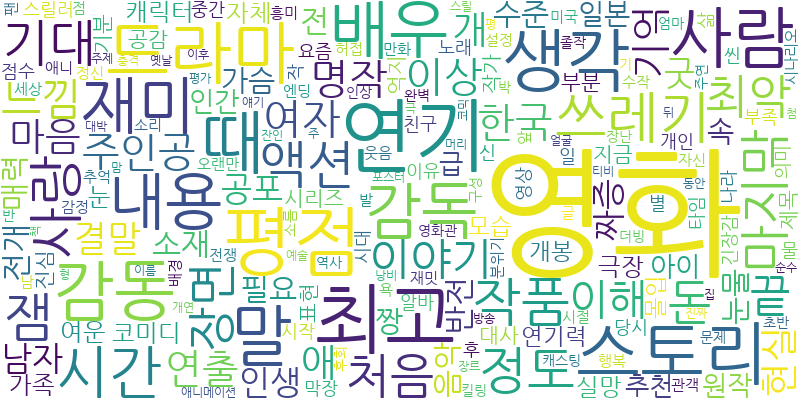

In [15]:
font = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
wc = WordCloud(font_path=font, width=800, height=400,
               background_color='white', random_state=0)
wc.generate_from_frequencies(n['nouns'].value_counts()).to_image()

구름의 한가운데를 `영화`가 차지했다. 이 말은 리뷰를 몇 편에나 나오는가?

- `n.groupby('nouns')['id'].nunique()`: 명사마다 **서로 다른 리뷰 `id`**가 몇 개인지 센다. 곧 8강의 **문서 빈도**다.
- `nlargest(4)`: 7강에서 쓴 것. 가장 큰 넷을 고른다.
- `len(df)`로 나누면 리뷰 가운데 몇 분의 몇에 나오는지가 된다.

`영화`는 리뷰의 **31.1%**에 나오고, 2위 `연기`는 4.4%에 나온다. 어디에나 나오는 말은 리뷰를 가르지 못한다. 20강의 TF-IDF가 이 생각을 수식으로 만든다.

In [16]:
docfreq = n.groupby('nouns')['id'].nunique()
top = docfreq.nlargest(4)
print((top / len(df)).round(3))

nouns
영화    0.311
연기    0.044
최고    0.041
평점    0.039
Name: id, dtype: float64


**불용어**(stopword)는 세지 않기로 **정한** 말이다. 정답 목록은 없다. Kiwi에도 불용어 목록(`kiwipiepy.utils.Stopwords`)이 있는데, 100개 가운데 대부분이 조사와 어미이고 명사는 `때`, `말`, `사람`, `일`, `지역` 다섯뿐이다.

오늘은 명사 가운데 `영화` 하나만 뺀다. 근거는 문서 빈도 31.1%다. `때`와 `말`도 뺄 수 있다. 다만 **무엇을 뺐는지 적어 둔다**. 8강의 "보고할 때 적어야 할 것"에 한 줄이 는다.

- `~n['nouns'].isin(stop)`: 불용어 집합에 **들지 않은** 행만 남긴다. `~`는 6강의 "아니다"다.
- `for` 문: `label`이 0이면 부정(`neg`), 1이면 긍정(`pos`)으로 나누어 상위 여덟 명사를 찍고 구름을 그린다.
- `generate_from_frequencies`는 구름 자신을 돌려주므로 `.to_file(...)`을 이어 붙여 그림 파일로 저장한다.

부정 쪽에는 `쓰레기`, 긍정 쪽에는 `최고`, `감동`이 있다. 여기까지는 짐작대로다. 그런데 부정 쪽 여덟째에 `재미`가 있다. `plots/nsmc-neg.png`를 열어 보면 왼쪽 아래에 크게 찍혀 있다.

In [17]:
stop = {'영화'}
n = n[~n['nouns'].isin(stop)]
for label, side in [(0, 'neg'), (1, 'pos')]:
    vc = n[n['label'] == label]['nouns'].value_counts()
    print(side, list(vc.index[:8]))
    wc.generate_from_frequencies(vc).to_file(f'plots/nsmc-{side}.png')

neg ['평점', '스토리', '연기', '쓰레기', '내용', '감독', '말', '재미']
pos ['최고', '연기', '감동', '때', '생각', '드라마', '사랑', '평점']


## 6. 구름이 감추는 것

`pd.crosstab`은 두 열의 값을 짝지어 센다. 7강의 `groupby`를 한 번에 한 셈이다.

두 구름에 다 있던 `연기`는 긍정 쪽이 조금 많고(5,337 대 4,419), `재미`는 **부정 쪽이 1.7배** 많다(3,569 대 2,089). 글자 크기는 한 구름 **안에서의** 순서만 보여 주므로, 구름 두 장을 나란히 놓아도 이것은 읽히지 않는다.

In [18]:
ct = pd.crosstab(n['nouns'], n['label'])
print(ct.loc[['최고', '감동', '재미',
              '연기', '쓰레기', '최악']])

label     0     1
nouns            
최고      640  8246
감동     1349  5143
재미     3569  2089
연기     4419  5337
쓰레기    4363   250
최악     2998    35


부정 리뷰 가운데 `재미`라는 글자가 든 것을 직접 읽어 본다.

- `&`: 두 조건을 모두 만족하는 행. 조건마다 괄호로 감싼다.
- `.str.contains('재미')`: 문자열에 `재미`가 들어 있는가

8,065편이고, 앞의 세 편은 모두 재미가 **없다**는 말이다. 부정 리뷰의 명사 `재미` 3,569번 뒤에는 `도`(874번), `없`(704번), `가`(643번)가 가장 많이 왔다. `재미도 없고`, `재미 없다`에서 명사만 고르면 **`없다`가 떨어져 나가고 `재미`만 남는다**.

In [19]:
neg = df[(df['label'] == 0) & df['document'].str.contains('재미')]
print(len(neg))
for d in neg['document'].head(3):
    print(d)

8065
재미없어 연기 넘 오글거려 ㅋㅋㅋ
전혀 재미도없고 진부한 공포영화
스토리도 그렇고 연기는 볼만한데 너무 재미없어요


띄어쓰기 하나가 세는 결과를 바꾼다.

붙여 쓰면 형용사 하나(`재미없/VA`), 띄어 쓰면 명사와 형용사 둘이다. 띄어쓰기 하나로 명사 `재미`가 생기고 사라진다. 부정 리뷰에 4,207번 나온 형용사 `재미없`은 명사 구름에 처음부터 없다. 긍정 쪽의 `재밌`(10,273번)과 `재미있`(4,628번)은 또 서로 다른 타입이다.

In [20]:
for r in ['재미없다', '재미 없다']:
    print([(t.form, t.tag) for t in kiwi.tokenize(r)])

[('재미없', 'VA'), ('다', 'EF')]
[('재미', 'NNG'), ('없', 'VA'), ('다', 'EF')]


### 단어구름을 읽을 때

- **크기**는 빈도에 비례하지 않는다. `영화`는 `연기`보다 8.0배 많이 나오는데 글자는 1.8배 크다(기본값 `relative_scaling=0.5`).
- **자리**와 색과 방향은 무작위다. `random_state`를 적어야 같은 그림이 다시 나온다.
- **맥락**은 남지 않는다. `재미`가 `재미없다`에서 왔는지 그림은 말하지 않는다.
- **비교**는 표로 한다. 구름 두 장의 같은 크기는 같은 빈도가 아니다.

개수를 견줄 때는 7강에서 본 대로 막대그림이 맞는 자리다. 단어구름은 첫인상을 얻는 그림이고, 결론은 교차표로 확인한 수로 쓴다.